import libraries

In [3]:
import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

load data from file

In [ ]:
datahead = ['user id', 'item id','rating','timestamp']
data = pd.read_csv(r'.\ml-100k\u.data', names=datahead, header=None, sep="\t")

movieshead = ["movie id", "movie title", "release date", "video release date",
              "IMDb URL", "unknown", "Action", "Adventure", "Animation",
              "Children's", "Comedy", "Crime", "Documentary", "Drama", "Fantasy",
              "Film-Noir", "Horror", "Musical", "Mystery", "Romance", "Sci-Fi",
              "Thriller", "War", "Western",]
movies = pd.read_csv(r'.\ml-100k\u.item', names=movieshead, header=None, sep='|')
movies.fillna(0, inplace=True)

merge data and movies dataframe

In [5]:
df = pd.merge(data, movies, right_on="movie id", left_on="item id") 

find movie stats like average rating and number rating

In [6]:
movie_stats = df.groupby('movie id').agg({
    'rating': ['mean', 'count']
}).reset_index()

movie_stats.columns = ['movie id', 'avrg_rating', 'num_rating']

remove duplicates and prepare final dataframe

In [7]:
genre = ["unknown", "Action", "Adventure", "Animation",
         "Children's", "Comedy", "Crime", "Documentary", "Drama", "Fantasy",
         "Film-Noir", "Horror", "Musical", "Mystery", "Romance", "Sci-Fi",
         "Thriller", "War", 'Western']

# Get one row per movie with genre columns
movie_features = df.drop_duplicates(subset='movie id')[['movie id', 'movie title'] + genre]

# Merge with rating stats
df_final = pd.merge(movie_features, movie_stats, on='movie id')

apply Kmean model to predict

In [8]:
# Select only features to cluster on (genres + avg_rating + num_rating)
features = genre + ['avrg_rating', 'num_rating']

model = KMeans(n_clusters=5, random_state=42)

# Fit predict on numeric features only
df_final["Cluster"] = model.fit_predict(df_final[features])

Visualize in 2D using PCA (Principal Component Analysis)
Reduces dimensions while preserving max variance

In [9]:
# PCA on the same features (no 'Cluster', no 'movie id')
pca = PCA(n_components=2)
components = pca.fit_transform(df_final[features])

df_final['PC1'] = components[:, 0]
df_final['PC2'] = components[:, 1]


Plot scatter clusters using sns

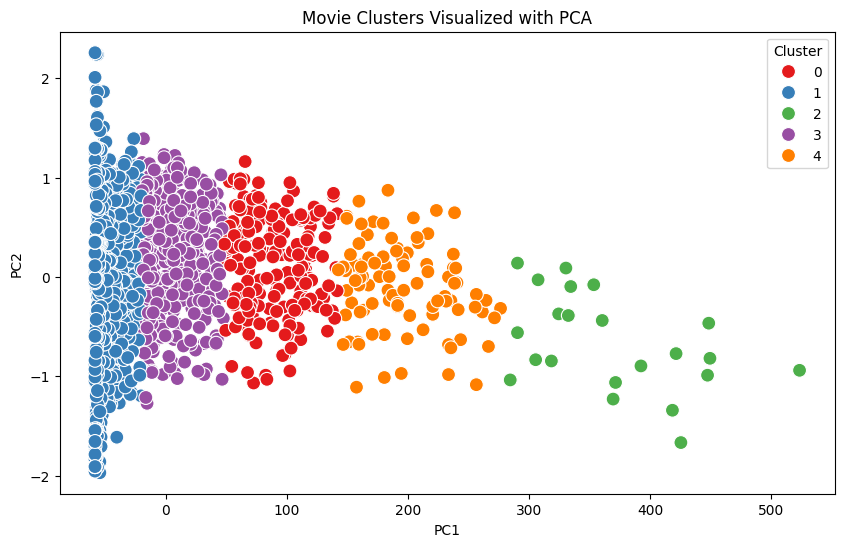

In [10]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_final, x='PC1', y='PC2', hue='Cluster', palette='Set1', s=100)
plt.title("Movie Clusters Visualized with PCA")
plt.show()

Recommend Movie based on given movie title

In [11]:
movie_cluster = df_final[df_final['movie title'] == 'Toy Story (1995)']['Cluster'].values[0]
recommended = df_final[df_final['Cluster'] == movie_cluster]
print(recommended)

     movie id                       movie title  unknown  Action  Adventure  \
12        222   Star Trek: First Contact (1996)        1       1          0   
24          1                  Toy Story (1995)        0       0          1   
31         98  Silence of the Lambs, The (1991)        0       0          0   
49        100                      Fargo (1996)        0       0          0   
52        181         Return of the Jedi (1983)        1       1          0   
60        288                     Scream (1996)        0       0          0   
77        237              Jerry Maguire (1996)        0       0          0   
95        294                  Liar Liar (1997)        0       0          0   
101       174    Raiders of the Lost Ark (1981)        1       1          0   
136       405        Mission: Impossible (1996)        1       1          0   
140       117                  Rock, The (1996)        1       1          0   
157       258                    Contact (1997)     